<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_100_multi_head_attention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 100/365 — Multi-Head Attention on a Real Dataset

Yesterday we implemented single-head self-attention with Query, Key and Value.

Today we compare:

- 1 attention head
- 4 attention heads

on the same real sunspot forecasting task.

The goal is to understand why Transformers use multiple heads.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from statsmodels.datasets import sunspots


## 1. Load and prepare the real dataset

In [2]:
data = sunspots.load_pandas().data.copy()

years = data["YEAR"].astype(int).values
values = data["SUNACTIVITY"].astype(np.float32).values.reshape(-1,1)

split = int(len(values) * 0.8)

scaler = MinMaxScaler()
scaler.fit(values[:split])

scaled = scaler.transform(values)

sequence_length = 12

X, y = [], []

for i in range(len(scaled) - sequence_length):
    X.append(scaled[i:i+sequence_length])
    y.append(scaled[i+sequence_length])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)

target_indices = np.arange(sequence_length, len(scaled))

train_mask = target_indices < split
test_mask = target_indices >= split

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]


In [3]:
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train),
        torch.tensor(y_train)
    ),
    batch_size=32,
    shuffle=True
)


## 2. Why multiple heads?

A single attention head learns one attention pattern.

Multi-head attention creates multiple sets of learned Q, K and V projections.

That allows different heads to learn different relationships in parallel.


## 3. Build the model

In [4]:
class MultiHeadModel(nn.Module):

    def __init__(
        self,
        heads=1,
        d_model=16
    ):
        super().__init__()

        self.input_projection = nn.Linear(
            1,
            d_model
        )

        self.position = nn.Parameter(
            torch.randn(
                1,
                sequence_length,
                d_model
            ) * 0.02
        )

        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=heads,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(d_model)

        self.feed_forward = nn.Sequential(
            nn.Linear(d_model,32),
            nn.ReLU(),
            nn.Linear(32,d_model)
        )

        self.norm2 = nn.LayerNorm(d_model)

        self.output = nn.Linear(
            d_model,
            1
        )

    def forward(
        self,
        x,
        return_attention=False
    ):

        z = (
            self.input_projection(x)
            + self.position
        )

        attention_output, weights = (
            self.attention(
                z,
                z,
                z,
                need_weights=True,
                average_attn_weights=False
            )
        )

        z = self.norm1(
            z + attention_output
        )

        z = self.norm2(
            z + self.feed_forward(z)
        )

        prediction = self.output(
            z.mean(dim=1)
        )

        if return_attention:
            return prediction, weights

        return prediction


## 4. Train and compare 1 head vs 4 heads

In [5]:
def train_model(
    heads,
    epochs=50
):

    torch.manual_seed(42)

    model = MultiHeadModel(
        heads=heads
    )

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.003
    )

    for epoch in range(epochs):

        model.train()

        for xb, yb in train_loader:

            optimizer.zero_grad()

            prediction = model(xb)

            loss = criterion(
                prediction,
                yb
            )

            loss.backward()

            optimizer.step()

    model.eval()

    with torch.no_grad():

        prediction_scaled, weights = (
            model(
                torch.tensor(X_test),
                return_attention=True
            )
        )

    prediction = scaler.inverse_transform(
        prediction_scaled.numpy()
    )

    actual = scaler.inverse_transform(
        y_test
    )

    mae = mean_absolute_error(
        actual.ravel(),
        prediction.ravel()
    )

    return model, prediction, weights, mae


In [6]:
results = {}

for heads in [1,4]:

    model, prediction, weights, mae = (
        train_model(heads)
    )

    results[heads] = {
        "model": model,
        "prediction": prediction,
        "weights": weights,
        "mae": mae
    }

    print(
        heads,
        "head(s) MAE:",
        round(mae,2)
    )


1 head(s) MAE: 17.23
4 head(s) MAE: 14.56


## 5. Compare test MAE

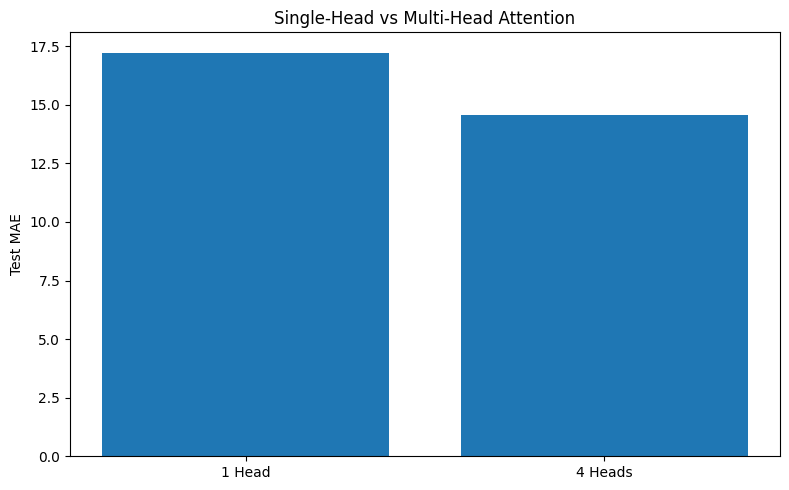

In [7]:
plt.figure(figsize=(8,5))

plt.bar(
    ["1 Head","4 Heads"],
    [
        results[1]["mae"],
        results[4]["mae"]
    ]
)

plt.ylabel("Test MAE")
plt.title("Single-Head vs Multi-Head Attention")
plt.tight_layout()
plt.show()


## 6. Inspect all four attention heads

The important output shape is:

`[batch, heads, query positions, key positions]`

That lets us inspect each head separately.


In [8]:
test_years = years[
    target_indices[test_mask]
]

example_idx = min(
    8,
    len(X_test)-1
)

target_year = test_years[
    example_idx
]

input_years = np.arange(
    target_year - sequence_length,
    target_year
)

weights = (
    results[4]["weights"][example_idx]
    .numpy()
)

print("Attention shape:", weights.shape)


Attention shape: (4, 12, 12)


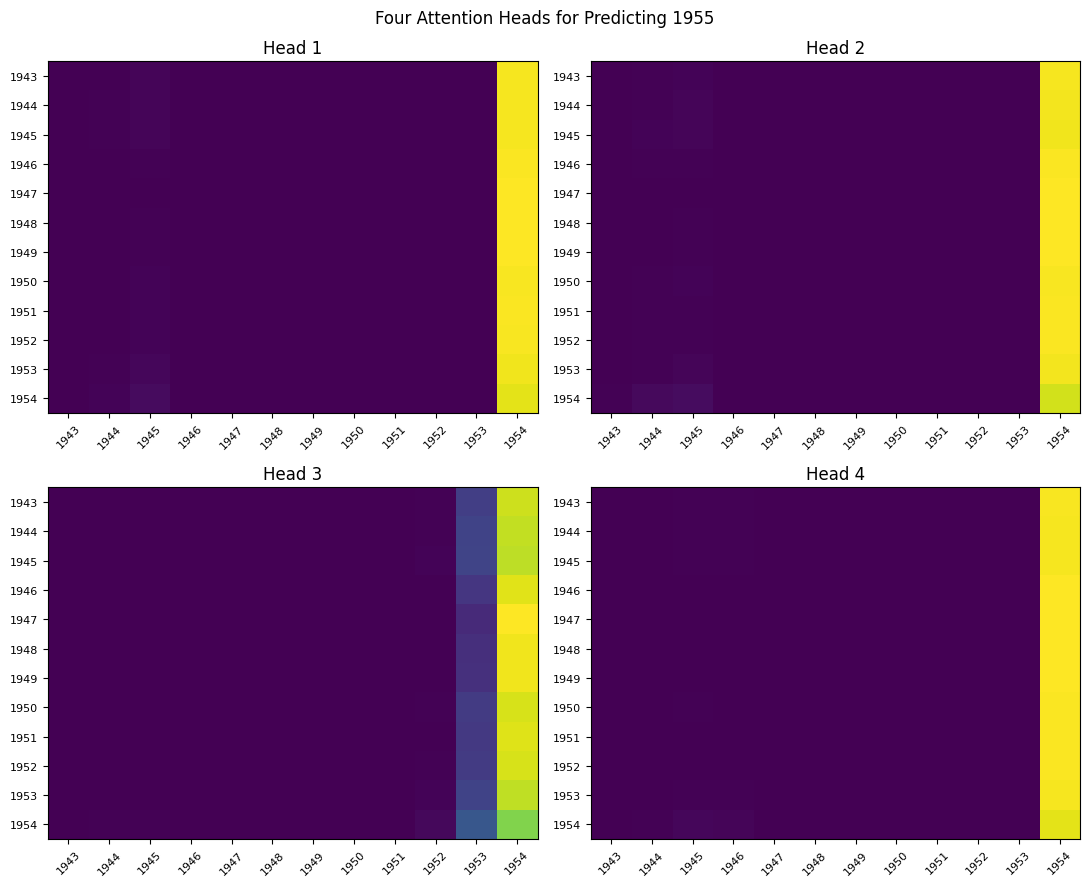

In [9]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(11,9)
)

for head, ax in enumerate(
    axes.ravel()
):

    ax.imshow(
        weights[head],
        aspect="auto"
    )

    ax.set_title(
        f"Head {head+1}"
    )

    ax.set_xticks(
        range(sequence_length)
    )

    ax.set_xticklabels(
        input_years,
        rotation=45,
        fontsize=8
    )

    ax.set_yticks(
        range(sequence_length)
    )

    ax.set_yticklabels(
        input_years,
        fontsize=8
    )

plt.suptitle(
    f"Four Attention Heads for Predicting {target_year}"
)

plt.tight_layout()
plt.show()


## 7. How are multiple heads combined?

Each head creates its own attended representation.

Those head outputs are concatenated and projected back into the model dimension.

Conceptually:

`head1 || head2 || head3 || head4`

This gives the model several attention perspectives at the same time.


## 8. More heads does not automatically mean better

Multiple heads increase representational flexibility.

But more heads do not guarantee lower error on every dataset.

The key benefit is:

**different heads can learn different relationships simultaneously.**


## Simple takeaway

Single-head attention asks:

**What should I focus on?**

Multi-head attention asks that question from several learned perspectives at once.

> **One head gives one attention view. Multiple heads let the model learn several views in parallel.**


## References

- Attention Is All You Need:
  https://arxiv.org/abs/1706.03762

- PyTorch MultiheadAttention:
  https://pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html

- The Illustrated Transformer:
  https://jalammar.github.io/illustrated-transformer/
